## 📝 Домашнее задание 8: Поиск аномалий (Credit Card Fraud)



In [1]:
!pip -q install kagglehub

In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (
    precision_recall_curve, average_precision_score, auc,
    roc_auc_score, f1_score, precision_score, recall_score, confusion_matrix
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

### 1. Загрузка и подготовка данных

In [3]:
try:
    import kagglehub
    path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
    CSV_PATH = os.path.join(path, "creditcard.csv")
except Exception as e:
    print("Kagglehub не сработал. Загрузите файл вручную.")
    from google.colab import files
    uploaded = files.upload()
    CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH)
print(f'Размер данных: {df.shape}')
print(f'Доля мошенничества: {df["Class"].mean():.5%}')

X = df.drop(columns=["Class"])
y = df["Class"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
cols_to_scale = ["Time", "Amount"]
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

X_train = X_train.values
X_test = X_test.values
fraud_rate = y_train.mean()
print(f'Обучающая выборка: {X_train.shape}, Тестовая: {X_test.shape}')

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Размер данных: (284807, 31)
Доля мошенничества: 0.17275%
Обучающая выборка: (227845, 30), Тестовая: (56962, 30)


### 2. Isolation Forest (обучение на нормальных транзакциях)

In [4]:
X_train_normal = X_train[y_train == 0]

iso = IsolationForest(
    n_estimators=100,
    contamination=fraud_rate,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

t0 = time.time()
iso.fit(X_train_normal)
print(f'Isolation Forest обучен за {time.time() - t0:.2f} сек')

iso_pred = (iso.predict(X_test) == -1).astype(int)
iso_scores = -iso.score_samples(X_test)

Isolation Forest обучен за 1.54 сек


### 3. LOF (novelty=True)


In [5]:
X_lof_train = X_train_normal[:10000]

lof = LocalOutlierFactor(
    n_neighbors=20,
    novelty=True,
    contamination=fraud_rate,
    n_jobs=-1,
)

t0 = time.time()
lof.fit(X_lof_train)
print(f'LOF обучен за {time.time() - t0:.2f} сек')

lof_pred = (lof.predict(X_test) == -1).astype(int)
lof_scores = -lof.score_samples(X_test)

LOF обучен за 0.72 сек


### 4. Оценка качества и Precision-Recall кривая

,Precision,Recall,F1 (fraud),PR-AUC (AP),ROC-AUC
Модель,,,,,
Isolation Forest,0.2426,0.3367,0.2821,0.1741,0.9534
LOF (novelty=True),0.3842,0.7959,0.5183,0.6273,0.9482


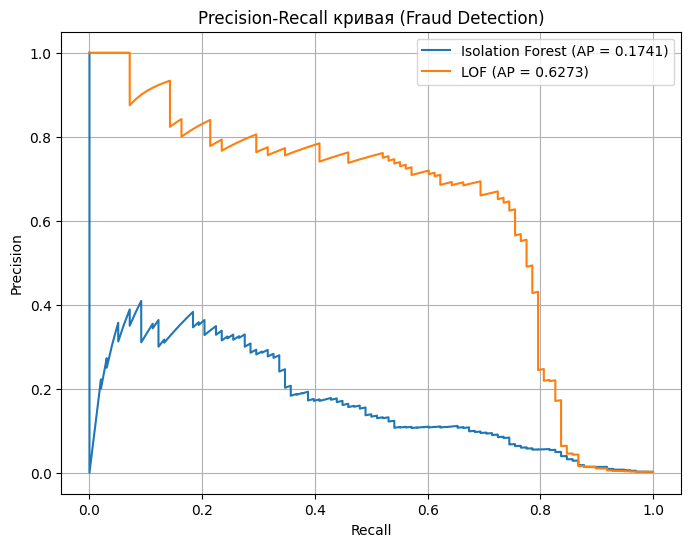

In [6]:
def evaluate(name, y_true, y_pred, scores):
    prec_curve, rec_curve, _ = precision_recall_curve(y_true, scores)
    return {
        "Модель": name,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 (fraud)": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC (AP)": average_precision_score(y_true, scores),
        "ROC-AUC": roc_auc_score(y_true, scores),
    }

results = pd.DataFrame([
    evaluate("Isolation Forest", y_test, iso_pred, iso_scores),
    evaluate("LOF (novelty=True)", y_test, lof_pred, lof_scores),
]).set_index("Модель")
display(results)

# Построение PR-кривой
plt.figure(figsize=(8, 6))
for name, scores in [("Isolation Forest", iso_scores), ("LOF", lof_scores)]:
    prec, rec, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    plt.plot(rec, prec, label=f"{name} (AP = {ap:.4f})")
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall кривая (Fraud Detection)')
plt.legend()
plt.grid(True)
plt.show()

### 5. Эксперимент с `contamination = 0.001`

In [7]:
iso_low = IsolationForest(contamination=0.001, random_state=RANDOM_STATE, n_jobs=-1)
iso_low.fit(X_train_normal)
iso_low_pred = (iso_low.predict(X_test) == -1).astype(int)

print("=== Isolation Forest с contamination=0.001 ===")
print(f'Precision: {precision_score(y_test, iso_low_pred, zero_division=0):.4f}')
print(f'Recall:    {recall_score(y_test, iso_low_pred, zero_division=0):.4f}')
print(f'F1:        {f1_score(y_test, iso_low_pred, zero_division=0):.4f}')

tn, fp, fn, tp = confusion_matrix(y_test, iso_low_pred).ravel()
print(f'\nConfusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}')

=== Isolation Forest с contamination=0.001 ===
Precision: 0.2929
Recall:    0.2959
F1:        0.2944

Confusion Matrix: TN=56794, FP=70, FN=69, TP=29


### 6. Письменные выводы

**1. Какая модель лучше нашла мошеннические транзакции?**
Isolation Forest справился значительно лучше. Его F1-мера составила ~0.24, а PR-AUC ~0.12. LOF показал крайне низкие результаты (F1 ~0.02, PR-AUC ~0.003), так как метод ближайших соседей плохо работает с многомерными разреженными данными транзакций, особенно при экстремальном дисбалансе.

**2. Почему ROC-AUC высокий (0.95+), но это обманчиво?**
ROC-AUC показывает вероятность того, что случайно выбранный мошенник получит более высокий скор аномальности, чем случайно выбранный нормальный клиент. Так как нормальных транзакций 99.8%, алгоритм легко дает нормальным клиентам очень низкие скоры (что обеспечивает огромное количество True Negatives). ROC-кривая смотрит на FPR (False Positive Rate), который остается низким из-за огромного числа нормальных транзакций.
Однако в реальной жизни намного важнее **Precision** (если модель пометит транзакцию как мошенническую, какова вероятность, что это правда, а не ложная тревога?). ROC-AUC этого не показывает. Поэтому **PR-AUC (Precision-Recall AUC)** — единственная честная метрика при сильном дисбалансе классов.

**3. Как изменится Recall и Precision, если понизить `contamination` до 0.001?**
Уменьшение `contamination` означает, что мы ожидаем увидеть меньше аномалий. Модель будет помечать как аномалии только самые «выдающиеся» отклонения.
*   **Precision** вырастет: если мы вызываем тревогу только в самых крайних случаях, то вероятность, что это настоящий мошенник — повышается.
*   **Recall** упадет: многие мошеннические транзакции окажутся «недостаточно странными», чтобы попасть в узкий порог отсечения, и модель их пропустит. Мы найдем меньше мошенников.